# 00 — Study area and boundary quality check

This notebook is the first step of the new CHT forest ecohydrology project. It **reads** the original shapefile, verifies that it contains three districts, checks geometry validity and makes a map. It does not change the original GIS files.

In [1]:
from pathlib import Path
import json
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / 'configs' / 'study_config.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Start JupyterLab from the project root or its notebooks folder.')
CONFIG = json.loads((ROOT / 'configs' / 'study_config.json').read_text(encoding='utf-8'))
boundary_file = ROOT / CONFIG['boundary_relative_path']
assert boundary_file.exists(), f'Missing boundary: {boundary_file}'
print('Project:', ROOT.resolve())
print('Boundary:', boundary_file.relative_to(ROOT))

Project: D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml
Boundary: data\boundaries\CHT_3_districts.shp


In [2]:
districts = gpd.read_file(boundary_file)
print('Features:', len(districts))
print('CRS:', districts.crs)
print('Geometry types:', districts.geom_type.value_counts().to_dict())
print('Name field:', CONFIG['district_name_field'])
display(districts[['adm2_name', 'adm2_pcode', 'area_sqkm']])

expected = set(CONFIG['expected_districts'])
actual = set(districts[CONFIG['district_name_field']].astype(str))
assert len(districts) == len(expected), 'Unexpected number of district features'
assert actual == expected, f'Expected {expected}, received {actual}'
assert districts.crs is not None, 'The boundary must declare a coordinate reference system'
assert not districts.geometry.isna().any(), 'Null district geometry found'
print('Geometry valid by district:')
display(districts[['adm2_name']].assign(geometry_valid=districts.geometry.is_valid.to_numpy()))
if not districts.geometry.is_valid.all():
    raise ValueError('At least one polygon is invalid. Inspect and document a correction before continuing.')

Features: 3
CRS: EPSG:4326
Geometry types: {'Polygon': 3}
Name field: adm2_name


,adm2_name,adm2_pcode,area_sqkm
0,Bandarban,BD2003,4591.013093
1,Khagrachhari,BD2046,2977.804706
2,Rangamati,BD2084,5643.298646


Geometry valid by district:


,adm2_name,geometry_valid
0,Bandarban,True
1,Khagrachhari,True
2,Rangamati,True


In [3]:
# EPSG:6933 is a global equal-area projection; do not compute polygon area in degrees.
areas = districts.to_crs('EPSG:6933').geometry.area / 1_000_000
summary = districts[['adm2_name', 'adm2_pcode', 'area_sqkm']].copy()
summary['calculated_area_km2'] = areas
summary['difference_from_source_km2'] = areas - summary['area_sqkm'].astype(float)
display(summary)

# Keep districts separate. Union only in memory for whole-study-area statistics.
merged = districts.geometry.union_all()
merged_gdf = gpd.GeoDataFrame({'name': ['CHT three-district study area']}, geometry=[merged], crs=districts.crs)
merged_area_km2 = merged_gdf.to_crs('EPSG:6933').geometry.area.iloc[0] / 1_000_000
print(f'Union area (equal-area projected): {merged_area_km2:,.2f} km²')
print('The union is in memory only; no input file has been modified.')

,adm2_name,adm2_pcode,area_sqkm,calculated_area_km2,difference_from_source_km2
0,Bandarban,BD2003,4591.013093,4591.013093,2.324305e-08
1,Khagrachhari,BD2046,2977.804706,2977.804706,-7.881908e-08
2,Rangamati,BD2084,5643.298646,5643.298646,-1.550461e-07


Union area (equal-area projected): 13,212.12 km²
The union is in memory only; no input file has been modified.


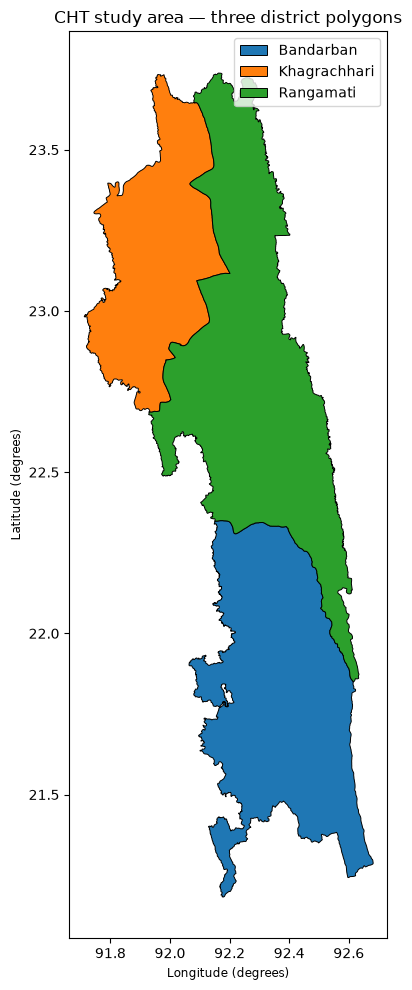

In [4]:
ax = districts.plot(column='adm2_name', legend=True, edgecolor='black', linewidth=0.7, figsize=(9, 10))
ax.set_title('CHT study area — three district polygons')
ax.set_xlabel('Longitude (degrees)')
ax.set_ylabel('Latitude (degrees)')
plt.tight_layout()
plt.show()

## Check before proceeding

Confirm the three names, district boundaries, geometry validity and calculated area. Compare the outlines with an authoritative boundary source and document the source/license before public redistribution. Do not proceed to full satellite exports until the study boundary is accepted.